# 04 | Model Development

Input: `organized_credit_data.csv`  |  Outputs: model evaluation and out-of-sample scores

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents) if (parent / "credit_risk_dataset.csv").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from the project folder containing credit_risk_dataset.csv.")
source = project_root / "organized_credit_data.csv"
if not source.exists():
    raise FileNotFoundError("Run 01_data_cleaning.ipynb and 02_data_organization.ipynb first.")
data = pd.read_csv(source)
target = "loan_status"
numeric_features = [
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]
categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file",
]
features = numeric_features + categorical_features
X = data[features]
y = data[target].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


def make_preprocessor():
    numeric = Pipeline(
        [("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    )
    categorical = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]
    )
    return ColumnTransformer(
        [("numeric", numeric, numeric_features), ("categorical", categorical, categorical_features)]
    )


def make_model(class_weight=None):
    return Pipeline(
        [
            ("preprocess", make_preprocessor()),
            ("classifier", LogisticRegression(max_iter=1000, class_weight=class_weight)),
        ]
    )


model = make_model()
balanced_model = make_model(class_weight="balanced")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring={"roc_auc": "roc_auc", "average_precision": "average_precision"},
    n_jobs=-1,
)
cv_summary = pd.DataFrame(
    {
        "metric": ["ROC AUC", "Average precision"],
        "mean": [
            cv_results["test_roc_auc"].mean(),
            cv_results["test_average_precision"].mean(),
        ],
        "std": [
            cv_results["test_roc_auc"].std(),
            cv_results["test_average_precision"].std(),
        ],
    }
)
display(cv_summary.round(3))
model.fit(X_train, y_train)
balanced_model.fit(X_train, y_train)

vif_preprocessor = make_preprocessor()
vif_matrix = vif_preprocessor.fit_transform(X_train)
vif_names = vif_preprocessor.get_feature_names_out()
vif_sample = pd.DataFrame(vif_matrix, columns=vif_names).sample(
    n=min(5000, len(X_train)), random_state=42
).astype(float)
vif_results = pd.DataFrame(
    {
        "feature": vif_sample.columns,
        "vif": [
            variance_inflation_factor(vif_sample.to_numpy(), i)
            for i in range(vif_sample.shape[1])
        ],
    }
).sort_values("vif", ascending=False)
display(vif_results.head(15).round(2))
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")

,metric,mean,std
0,ROC AUC,0.806,0.006
1,Average precision,0.626,0.012


,feature,vif
3,numeric__loan_percent_income,2.49
2,numeric__loan_amnt,2.47
8,categorical__loan_intent_EDUCATION,1.78
0,numeric__person_income,1.73
10,categorical__loan_intent_MEDICAL,1.72
12,categorical__loan_intent_VENTURE,1.71
11,categorical__loan_intent_PERSONAL,1.68
9,categorical__loan_intent_HOMEIMPROVEMENT,1.47
7,categorical__person_home_ownership_RENT,1.25
6,categorical__person_home_ownership_OWN,1.16


Train rows: 25,932; test rows: 6,484


## Test-set evaluation and score output

,model,roc_auc,gini,ks,average_precision,brier_score
0,Logistic regression,0.802,0.604,0.460,0.626,0.125
1,Class-weighted logistic regression,0.804,0.608,0.462,0.621,0.173


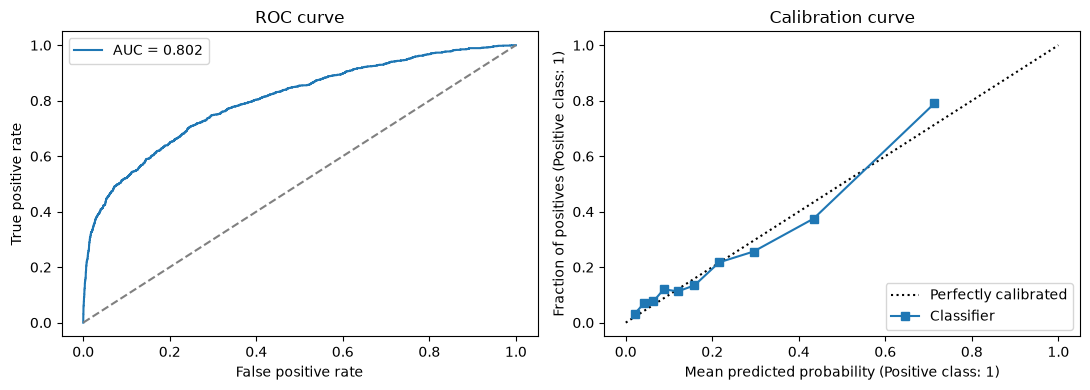

,threshold,flagged_share,default_recall,default_precision
0,0.2,0.374,0.726,0.424
1,0.3,0.243,0.590,0.531
2,0.4,0.168,0.495,0.643
3,0.5,0.115,0.393,0.749
4,0.6,0.078,0.303,0.846


,Predicted 0,Predicted 1
Actual 0,4879,187
Actual 1,861,557


,feature,coefficient,abs_coefficient
6,categorical__person_home_ownership_OWN,-1.353,1.353
3,numeric__loan_percent_income,1.181,1.181
13,categorical__cb_person_default_on_file_Y,1.118,1.118
12,categorical__loan_intent_VENTURE,-0.883,0.883
7,categorical__person_home_ownership_RENT,0.863,0.863
8,categorical__loan_intent_EDUCATION,-0.710,0.710
5,categorical__person_home_ownership_OTHER,0.646,0.646
11,categorical__loan_intent_PERSONAL,-0.509,0.509
2,numeric__loan_amnt,-0.375,0.375
9,categorical__loan_intent_HOMEIMPROVEMENT,0.217,0.217


Saved test scores, explainability, and combined model performance tables to powerbi_exports.


In [6]:
def evaluate(fitted_model, label):
    probability = fitted_model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probability)
    auc = roc_auc_score(y_test, probability)
    return {
        "model": label,
        "roc_auc": auc,
        "gini": 2 * auc - 1,
        "ks": float(np.max(tpr - fpr)),
        "average_precision": average_precision_score(y_test, probability),
        "brier_score": brier_score_loss(y_test, probability),
    }


metrics = pd.DataFrame(
    [
        evaluate(model, "Logistic regression"),
        evaluate(balanced_model, "Class-weighted logistic regression"),
    ]
)
display(metrics.round(3))
test_probability = model.predict_proba(X_test)[:, 1]
train_probability = model.predict_proba(X_train)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y_test, test_probability)
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, test_probability):.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()
CalibrationDisplay.from_predictions(
    y_test, test_probability, n_bins=10, strategy="quantile", ax=axes[1]
)
axes[1].set_title("Calibration curve")
plt.tight_layout()
plt.show()

threshold_rows = []
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60]:
    predicted = (test_probability >= threshold).astype(int)
    threshold_rows.append(
        {
            "threshold": threshold,
            "flagged_share": predicted.mean(),
            "default_recall": recall_score(y_test, predicted, zero_division=0),
            "default_precision": precision_score(y_test, predicted, zero_division=0),
        }
    )
threshold_analysis = pd.DataFrame(threshold_rows)
display(threshold_analysis.round(3))
display(
    pd.DataFrame(
        confusion_matrix(y_test, test_probability >= 0.50),
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"],
    )
)

points_to_double_odds = 20
base_score = 600
base_good_to_bad_odds = 50
score_factor = points_to_double_odds / np.log(2)
score_offset = base_score - score_factor * np.log(base_good_to_bad_odds)
log_odds_default = model.named_steps["classifier"].decision_function(
    model.named_steps["preprocess"].transform(X_test)
)
scorecard_points = np.rint(score_offset - score_factor * log_odds_default).astype(int)

feature_names = model.named_steps["preprocess"].get_feature_names_out()
feature_importance = pd.DataFrame(
    {
        "feature": feature_names,
        "coefficient": model.named_steps["classifier"].coef_[0],
    }
)
feature_importance["abs_coefficient"] = feature_importance["coefficient"].abs()
feature_importance = feature_importance.sort_values("abs_coefficient", ascending=False)
display(feature_importance.head(15).round(3))

scored_test = X_test.copy()
scored_test.insert(0, "source_row_id", X_test.index)
scored_test["actual_default"] = y_test.to_numpy()
scored_test["predicted_default_probability"] = test_probability
scored_test["scorecard_points"] = scorecard_points
scored_test["predicted_default_at_050"] = (test_probability >= 0.50).astype(int)
scored_test["risk_band_relative"] = pd.qcut(
    pd.Series(test_probability).rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"],
).to_numpy()

edges = np.linspace(0, 1, 11)
expected_share = np.histogram(train_probability, bins=edges)[0] / len(train_probability)
actual_share = np.histogram(test_probability, bins=edges)[0] / len(test_probability)
expected_share = np.clip(expected_share, 1e-6, None)
actual_share = np.clip(actual_share, 1e-6, None)
psi_value = float(np.sum((actual_share - expected_share) * np.log(actual_share / expected_share)))

performance_rows = []
for _, row in cv_summary.iterrows():
    performance_rows.append(
        {
            "model": "Logistic regression",
            "evaluation": "cross_validation",
            "metric": row["metric"],
            "threshold": np.nan,
            "value": row["mean"],
            "std": row["std"],
        }
    )
for _, row in metrics.iterrows():
    for metric_name in ["roc_auc", "gini", "ks", "average_precision", "brier_score"]:
        performance_rows.append(
            {
                "model": row["model"],
                "evaluation": "test_set",
                "metric": metric_name,
                "threshold": np.nan,
                "value": row[metric_name],
                "std": np.nan,
            }
        )
for _, row in threshold_analysis.iterrows():
    for metric_name in ["flagged_share", "default_recall", "default_precision"]:
        performance_rows.append(
            {
                "model": "Logistic regression",
                "evaluation": "threshold_analysis",
                "metric": metric_name,
                "threshold": row["threshold"],
                "value": row[metric_name],
                "std": np.nan,
            }
        )
performance_rows.append(
    {
        "model": "Logistic regression",
        "evaluation": "random_train_vs_test",
        "metric": "psi",
        "threshold": np.nan,
        "value": psi_value,
        "std": np.nan,
    }
)
model_performance = pd.DataFrame(performance_rows)

output = project_root / "powerbi_exports"
output.mkdir(exist_ok=True)
scored_test.to_csv(output / "scored_test_customers.csv", index=False)
feature_importance.to_csv(output / "feature_importance.csv", index=False)
model_performance.to_csv(output / "model_performance.csv", index=False)
print("Saved test scores, explainability, and combined model performance tables to powerbi_exports.")